# 3.5. Concise Implementation of Linear Regression

In [1]:
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

## 3.5.1. Defining the Model

In [2]:
class LinearRegression(d2l.Module):
    """The linear regression model implemented with high-level APIs."""

    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.LazyLinear(1)
        self.net.weight.data.normal_(0, 0.01)
        self.net.bias.data.fill_(0)

In [3]:
@d2l.add_to_class(LinearRegression)
def forward(self, X):
    return self.net(X)

## 3.5.2. Defining the Loss Function

In [4]:
@d2l.add_to_class(LinearRegression)
def loss(self, y_hat, y):
    fn = nn.MSELoss()
    return fn(y_hat, y)

## 3.5.3. Defining the Optimization Algorithm

In [5]:
@d2l.add_to_class(LinearRegression)
def configure_optimizers(self):
    return torch.optim.SGD(self.parameters(), self.lr)

## 3.5.4. Training

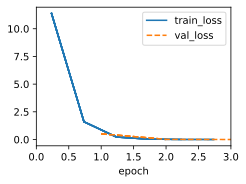

In [6]:
model = LinearRegression(lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

In [7]:
@d2l.add_to_class(LinearRegression)
def get_w_b(self):
    return (self.net.weight.data, self.net.bias.data)
w, b = model.get_w_b()

print(f"error in estimating w: {data.w - w.reshape(data.w.shape)}")
print(f"error in estimating b: {data.b - b}")

error in estimating w: tensor([ 0.0013, -0.0097])
error in estimating b: tensor([0.0108])


## 3.5.6. Exercises

error in estimating w: tensor([ 0.0266, -0.0390])
error in estimating b: tensor([0.0242])


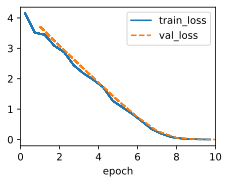

In [13]:
class LinearRegressionWithHuber(d2l.Module):
    """Linear Regression with Huber's robust loss"""

    def __init__(self, lr=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.LazyLinear(1)
        self.net.weight.data.normal_(0, 0.01)
        self.net.bias.data.fill_(0)

    def forward(self, X):
        return self.net(X)

    def loss(self, y_hat, y):
        return nn.HuberLoss(reduction='mean', delta=1)(y_hat, y)

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), self.lr)

    def get_w_b(self):
        return self.net.weight.data, self.net.bias.data

model = LinearRegressionWithHuber(lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

w, b = model.get_w_b()

print(f"error in estimating w: {data.w - w.reshape(data.w.shape)}")
print(f"error in estimating b: {data.b - b}")